<!-- @format -->

# Garbage Classification

## 1. Exploratory Data Analysis (EDA)

Phần này trình bày tổng quan dữ liệu ảnh, phân phối các lớp, chất lượng ảnh và các vấn đề cần xử lý trước khi huấn luyện mô hình.

### 1.1. Load dataset

Dataset được tải từ Kaggle bằng `kagglehub`, sau đó tự động xác định thư mục ảnh (bản gốc đã sửa nhãn và bản enhanced) cùng file CSV ghi lại các nhãn được sửa.

In [13]:
# [EDA 1.1] Tải dataset từ Kaggle
import kagglehub

path = kagglehub.dataset_download(
    "huberthamelin/garbage-classification-labels-corrections",
    output_dir="../data/raw",   # đường dẫn tính từ thư mục notebooks/
)
print("Path to dataset files:", path)

Path to dataset files: ../data/raw


In [14]:
# [EDA 1.1] Xác định thư mục ảnh, chọn bản enhanced làm dữ liệu chính
import sys, os
sys.path.insert(0, os.path.abspath('..'))
import modules.eda as eda

img_dirs, csv_files = eda.find_dataset("../data/raw")

# Nếu tên thư mục khác với kết quả in ở trên, chỉnh lại hai dòng này
ENHANCED_KEY = next(k for k in img_dirs if "enhanced" in k.lower())
ORIGINAL_KEY = next(k for k in img_dirs if k != ENHANCED_KEY)

df = eda.build_image_df(img_dirs[ENHANCED_KEY])
df_orig = eda.build_image_df(img_dirs[ORIGINAL_KEY])

Thư mục ảnh:
  - garbage_classification_corrected: ../data/raw/garbage_classification_corrected
  - garbage_classification_enhanced: ../data/raw/garbage_classification_enhanced
File CSV:
  - ../data/raw/labels_corrections.csv
Dataset shape: (15870, 4)
Số lớp  : 12
Các lớp : ['battery', 'biological', 'brown-glass', 'cardboard', 'clothes', 'green-glass', 'metal', 'paper', 'plastic', 'shoes', 'trash', 'white-glass']

File extension:
ext
.jpg    15870
Name: count, dtype: int64
Dataset shape: (15467, 4)
Số lớp  : 12
Các lớp : ['battery', 'biological', 'brown-glass', 'cardboard', 'clothes', 'green-glass', 'metal', 'paper', 'plastic', 'shoes', 'trash', 'white-glass']

File extension:
ext
.jpg    15467
Name: count, dtype: int64


<!-- @format -->

Kết quả cho thấy bản `enhanced` có `15,870` ảnh và bản `corrected` có `15,467` ảnh, cùng gồm `12` lớp và toàn bộ file đều ở định dạng `.jpg`. Nhãn của ảnh được lấy từ tên thư mục lớp, và file `labels_corrections.csv` ghi lại các ảnh đã được sửa nhãn.

Theo mô tả nguồn dữ liệu, bản `enhanced` gồm bản `corrected` cộng thêm ảnh mới từ web. Vì vậy nhóm chỉ dùng bản `enhanced` làm dữ liệu chính, còn bản `corrected` chỉ để đối chiếu, tránh trộn hai bản gây trùng ảnh.

<!-- @format -->

### 1.2. Image integrity and properties

Phần này đọc từng ảnh để kiểm tra ảnh lỗi, đồng thời thu thập kích thước, chế độ màu (mode) và dung lượng file phục vụ các phân tích phía sau.

In [15]:
# [EDA 1.2] Kiểm tra ảnh lỗi và trích xuất thuộc tính ảnh
df = eda.add_image_properties(df)

Ảnh lỗi / không đọc được: 0

Image mode:
mode
RGB     15757
RGBA       80
P          33
Name: count, dtype: int64


<!-- @format -->

Kết quả cho thấy không có ảnh nào bị lỗi hoặc không đọc được. Tuy nhiên có `113` ảnh không ở chế độ `RGB`, gồm `80` ảnh `RGBA` và `33` ảnh `P` (palette), chiếm khoảng `0.7%` dataset.

Nếu không xử lý, các ảnh này sẽ có số kênh khác `3` và gây lỗi khi gom batch. Do đó ở các bước xử lý, nhóm sẽ chú ý chuyển toàn bộ ảnh về `RGB` ngay khi đọc.

<!-- @format -->

### 1.3. Class distribution

Phần này kiểm tra số lượng ảnh của từng lớp để đánh giá mức độ mất cân bằng giữa các lớp.

Class counts & percentages:
             count  percent (%)
label                          
clothes       5286        33.31
shoes         2006        12.64
paper         1108         6.98
biological    1035         6.52
battery        979         6.17
cardboard      936         5.90
plastic        901         5.68
metal          837         5.27
white-glass    796         5.02
trash          726         4.57
green-glass    641         4.04
brown-glass    619         3.90

Imbalance ratio (max/min): 8.54


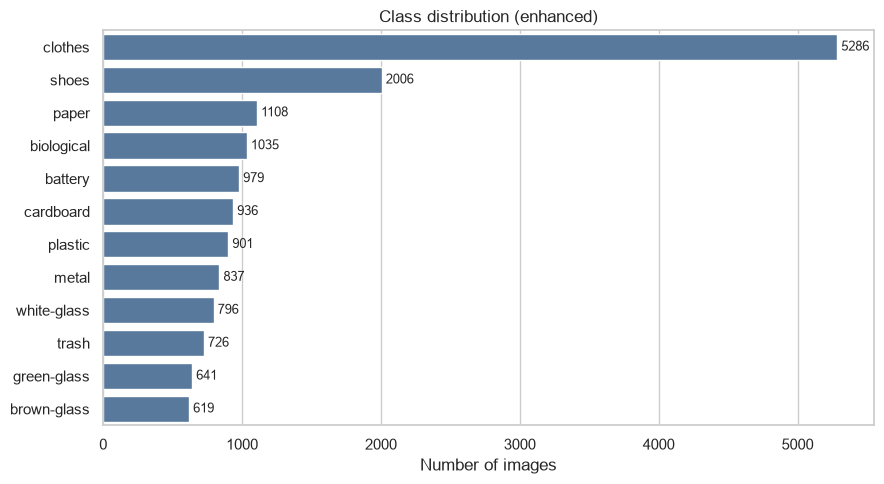

In [16]:
# [EDA 1.3] Phân phối các lớp (bản enhanced)
eda.plot_class_distribution(df, title="Class distribution (enhanced)")

<!-- @format -->

Kết quả cho thấy dataset mất cân bằng rõ rệt, với tỷ lệ giữa lớp lớn nhất và nhỏ nhất là `8.54`. Lớp `clothes` chiếm `33.31%` (`5,286` ảnh) và `shoes` chiếm `12.64%` (`2,006` ảnh), hai lớp này cộng lại gần `46%` dataset. Mười lớp còn lại chỉ chiếm từ `3.90%` đến `6.98%`, nhỏ nhất là `brown-glass` (`619` ảnh) và `green-glass` (`641` ảnh).

Do đó một mô hình dự đoán toàn bộ là `clothes` cũng đã đạt khoảng `33%` accuracy. Vì vậy cần chia dữ liệu theo stratified và đánh giá bằng `macro-F1`, recall theo từng lớp và confusion matrix, thay vì chỉ dựa vào accuracy.

<!-- @format -->

### 1.4. Original vs enhanced

Phần này so sánh số ảnh mỗi lớp giữa bản gốc đã sửa nhãn và bản enhanced để biết lớp nào được bổ sung thêm ảnh.

             original  enhanced  diff
label                                
clothes          5286      5286     0
shoes            2007      2006    -1
paper            1043      1108    65
biological        983      1035    52
battery           944       979    35
cardboard         896       936    40
plastic           864       901    37
metal             767       837    70
white-glass       764       796    32
trash             697       726    29
green-glass       613       641    28
brown-glass       603       619    16

Tổng: {'original': 15467, 'enhanced': 15870}


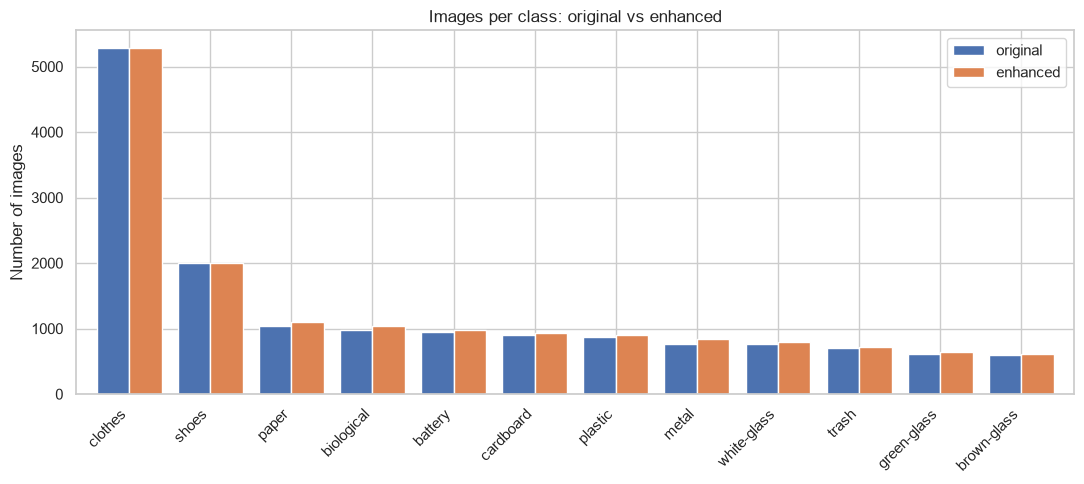

In [17]:
# [EDA 1.4] So sánh số ảnh mỗi lớp giữa hai phiên bản
eda.compare_class_distribution({"original": df_orig, "enhanced": df})

<!-- @format -->

Kết quả cho thấy bản `enhanced` bổ sung thêm `403` ảnh so với bản `corrected` (`15,467` lên `15,870`). Ảnh mới được thêm vào `10/12` lớp, nhiều nhất ở `metal` (`+70`, khoảng `+9.1%`) và `paper` (`+65`, khoảng `+6.2%`), ít nhất ở `brown-glass` (`+16`). Lớp `clothes` không đổi, còn `shoes` giảm `1` ảnh.

Vì lớp lớn nhất không được bổ sung nên mức mất cân bằng gần như không cải thiện (từ khoảng `8.77` xuống `8.54`). Việc bổ sung ảnh không thay thế được các biện pháp xử lý mất cân bằng ở bước huấn luyện.

<!-- @format -->

### 1.5. Label corrections

Phần này xem file CSV ghi lại các ảnh bị sửa nhãn trong bản gốc.

In [18]:
# [EDA 1.5] Đọc file CSV các nhãn đã sửa
import pandas as pd

# File dùng dấu ';' làm phân cách và có BOM nên cần sep và encoding
corr = pd.read_csv(csv_files[0], sep=";", encoding="utf-8-sig")
print("Shape:", corr.shape)
print("Columns:", list(corr.columns))
corr.head(10)

Shape: (70, 3)
Columns: ['Old Label', 'Nb', 'New Label']


,Old Label,Nb,New Label
0,paper,956,cardboard
1,clothes,4635,shoes
2,clothes,2733,shoes
3,white-glass,58,multiple
4,clothes,2556,shoes
5,clothes,2654,shoes
6,clothes,4293,shoes
7,clothes,5201,shoes
8,paper,578,cardboard
9,shoes,82,unknown


Tổng số ảnh được sửa nhãn: 70

Top các cặp sửa nhãn:
Old Label    New Label  
clothes      shoes          38
white-glass  multiple        6
paper        cardboard       5
white-glass  unknown         5
shoes        unknown         2
metal        multiple        2
paper        plastic         2
biological   unknown         2
white-glass  green-glass     1
plastic      multiple        1
dtype: int64


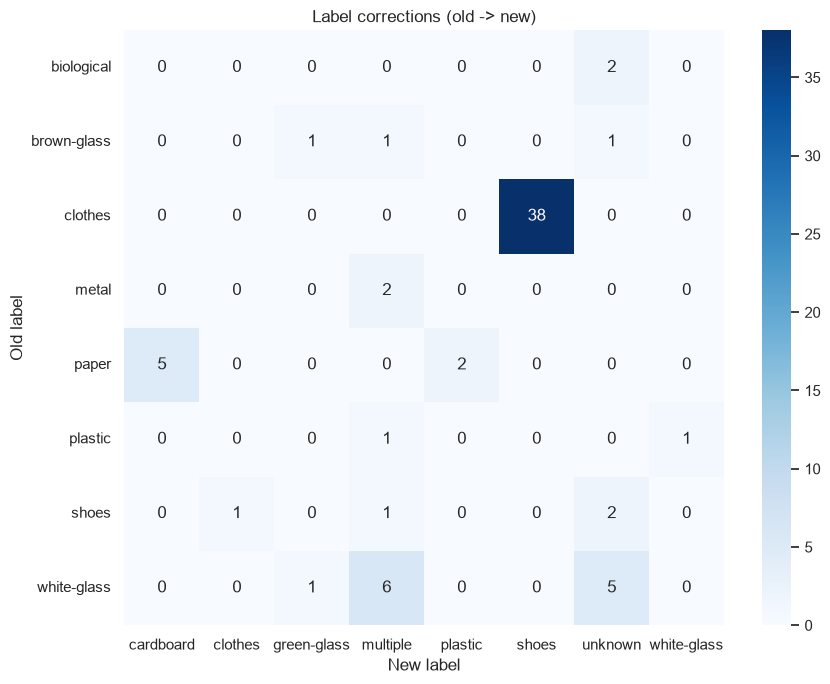

In [19]:
# [EDA 1.5] Ma trận sửa nhãn (nhãn cũ -> nhãn mới), mỗi dòng của CSV là một ảnh
OLD_COL, NEW_COL = "Old Label", "New Label"
eda.plot_correction_matrix(corr, OLD_COL, NEW_COL)

<!-- @format -->

Kết quả cho thấy file `labels_corrections.csv` có `70` dòng, tương ứng `70` ảnh được sửa nhãn, tức dưới `0.5%` dataset. Cột `Nb` là số thứ tự của ảnh trong bộ gốc chứ không phải số lượng, nên mỗi dòng được đếm là một ảnh.

<!-- @format -->

### 1.6. Sample images

Phần này hiển thị ngẫu nhiên một số ảnh của từng lớp để quan sát trực quan nền ảnh, góc chụp và mức độ đa dạng trong cùng một lớp.

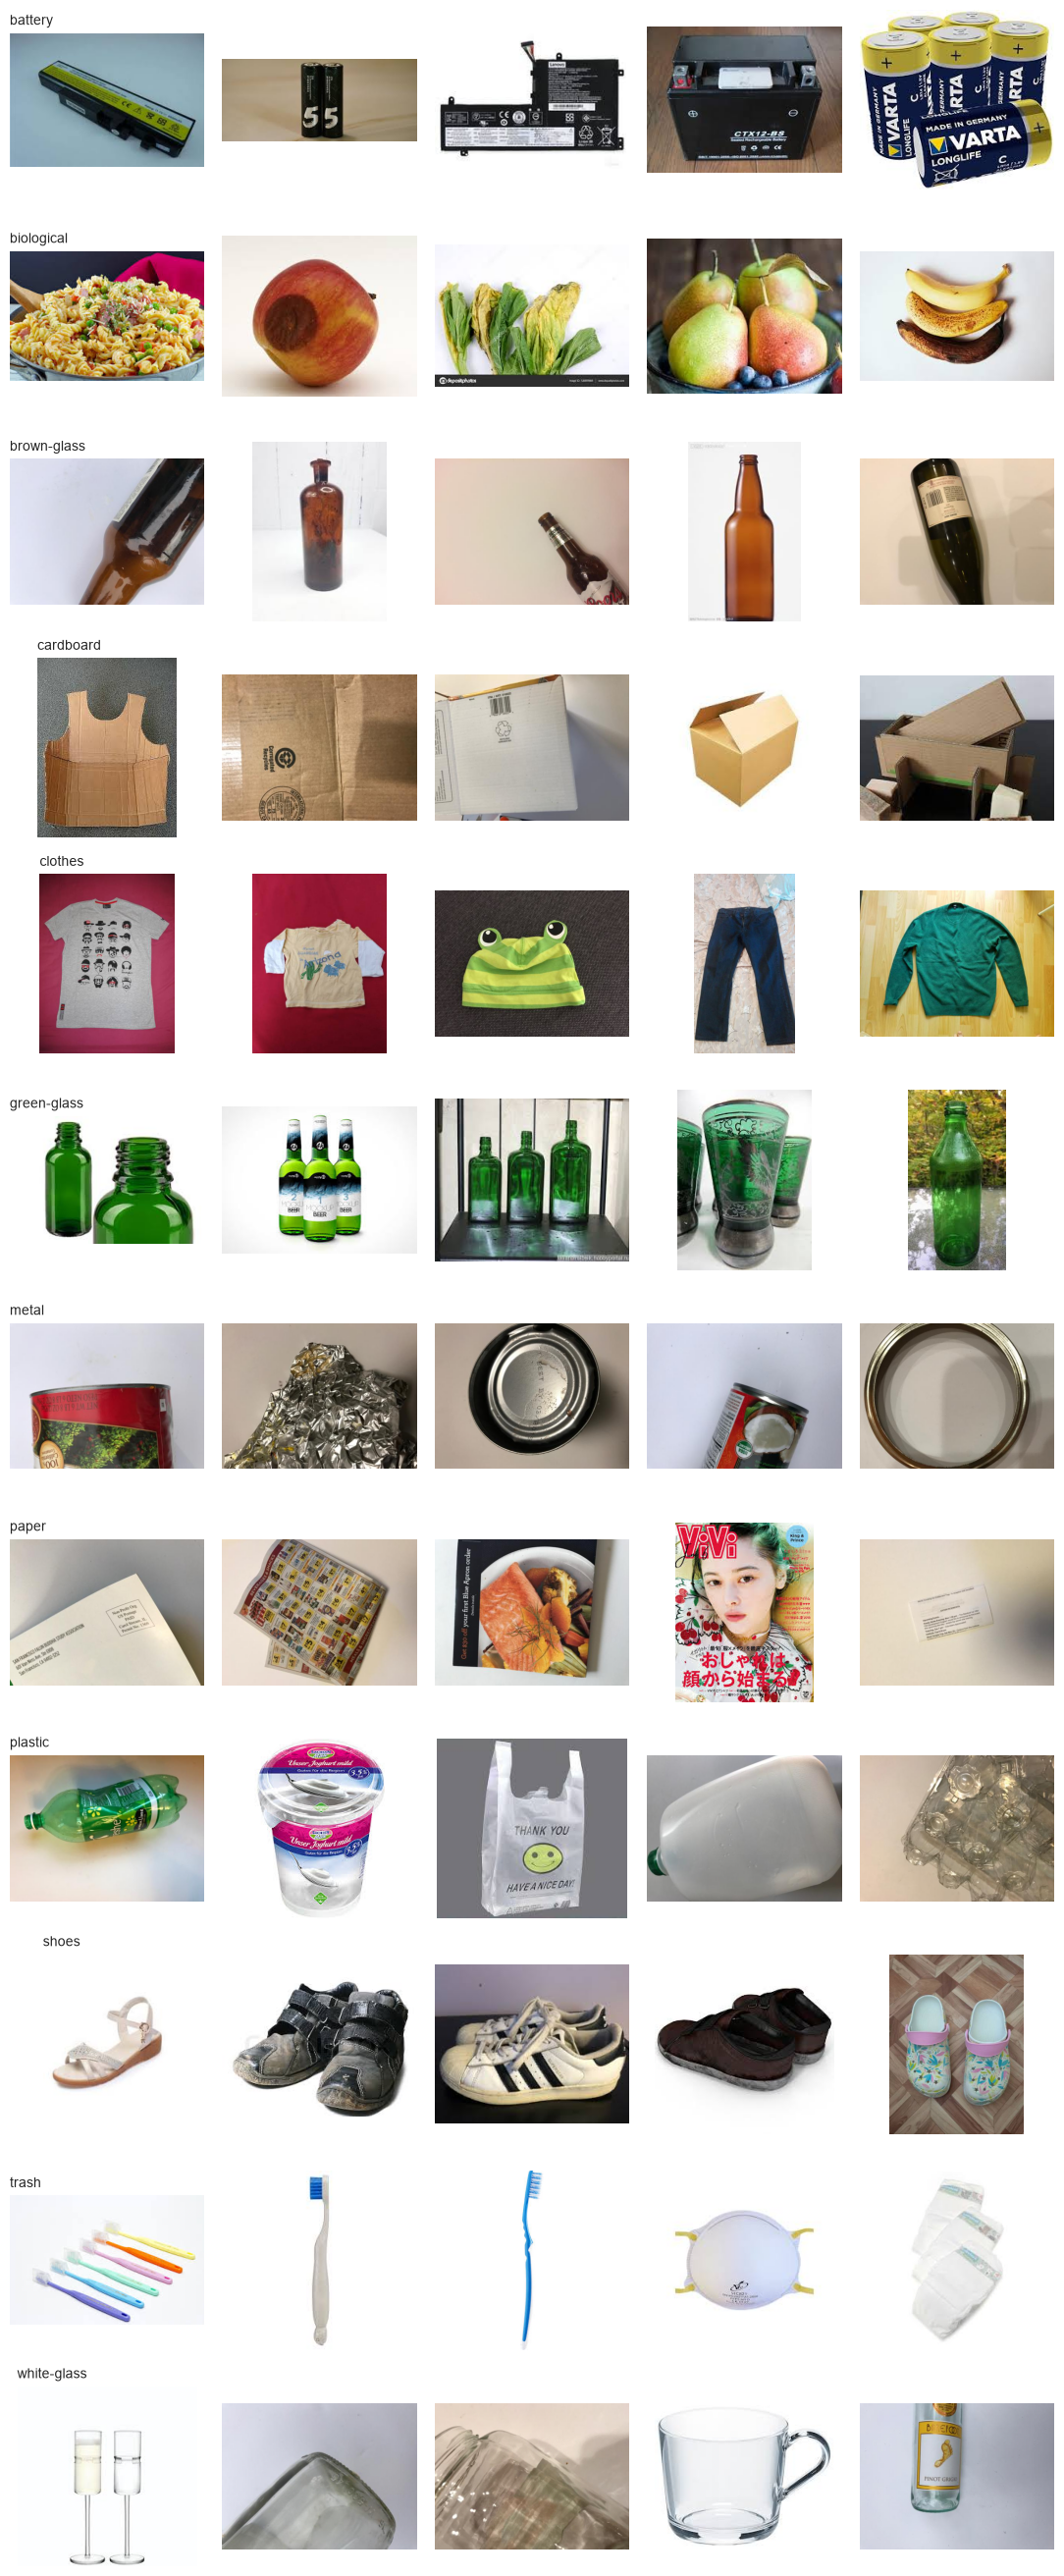

In [20]:
# [EDA 1.6] Lưới ảnh mẫu theo lớp
eda.show_sample_images(df, n_per_class=5)

<!-- @format -->

### 1.7. Image size and aspect ratio

Phần này khảo sát kích thước, tỷ lệ khung hình và dung lượng ảnh để quyết định kích thước resize ở bước preprocessing.

          width    height  aspect_ratio   size_kb
count  15870.00  15870.00      15870.00  15870.00
mean     350.87    351.52          1.09     16.63
std      117.44    148.52          0.35     18.17
min       51.00    100.00          0.13      1.05
25%      237.00    225.00          0.75      5.92
50%      400.00    384.00          1.00     13.02
75%      400.00    533.00          1.33     22.97
max     1000.00    990.00          5.02    675.24

Top 5 kích thước phổ biến nhất (width x height):
400x533    2592
512x384    2356
225x225    1992
400x534    1078
275x183     685
Name: count, dtype: int64


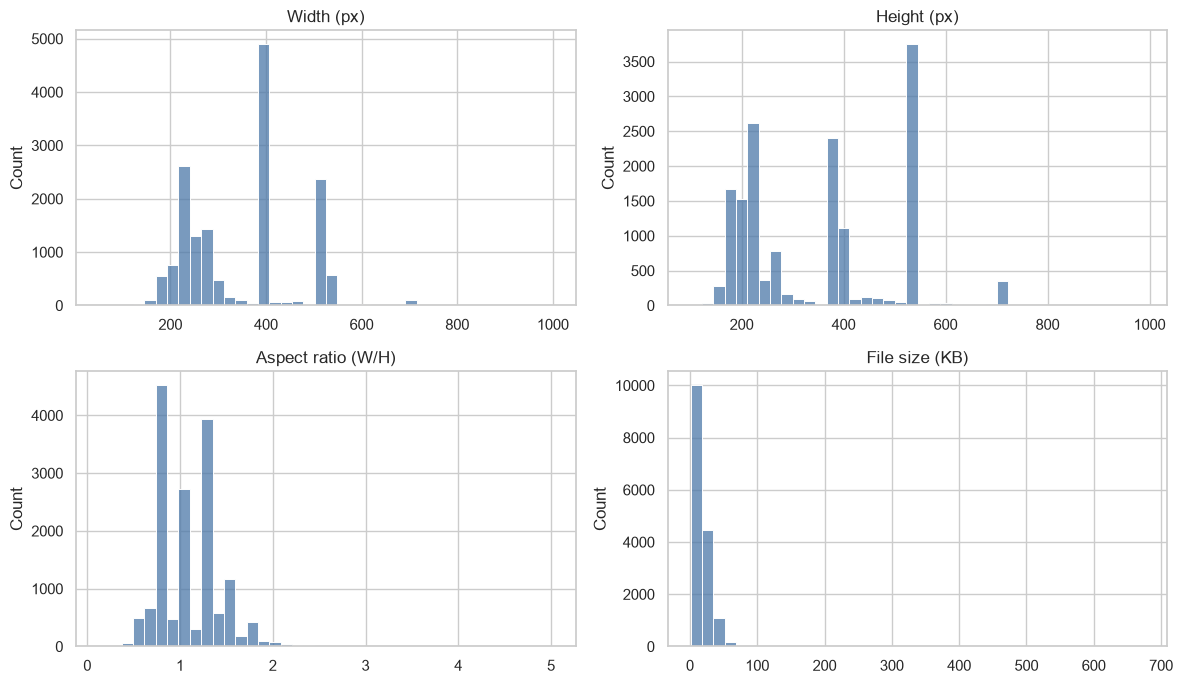

In [21]:
# [EDA 1.7] Phân phối width, height, aspect ratio, dung lượng file
eda.plot_image_size_distribution(df)

In [22]:
# [EDA 1.7] Kiểm tra các kích thước phổ biến có gắn với lớp cụ thể hay không
d = df[df["is_valid"]].copy()
d["size"] = d["width"].astype(int).astype(str) + "x" + d["height"].astype(int).astype(str)
top_sizes = d["size"].value_counts().head(5).index
sub = d[d["size"].isin(top_sizes)]
pd.crosstab(sub["size"], sub["label"])

label,battery,biological,brown-glass,cardboard,clothes,green-glass,metal,paper,plastic,shoes,trash,white-glass
size,,,,,,,,,,,,
225x225,380,63,180,136,0,132,127,14,90,370,307,193
275x183,64,204,16,34,0,23,32,23,33,180,60,16
400x533,0,0,0,0,2441,0,3,0,0,148,0,0
400x534,0,0,0,0,896,1,0,0,0,181,0,0
512x384,1,1,114,408,0,80,410,587,479,0,0,276


<!-- @format -->

Kết quả cho thấy kích thước ảnh không phân bố liên tục mà tập trung thành vài cụm rõ rệt: chiều rộng quanh `225`, `275`, `400`, `512` và chiều cao quanh `225`, `384`, `533`. Năm kích thước phổ biến nhất (`400x533`, `512x384`, `225x225`, `400x534`, `275x183`) chiếm khoảng `55%` dataset, cho thấy ảnh đến từ một số nguồn với độ phân giải cố định. Tỷ lệ khung hình tập trung ở ba mức `0.75` (dọc), `1.0` (vuông) và `1.33` (ngang), với median `1.0`. Một số ít ảnh có tỷ lệ cực đoan (từ `0.13` đến `5.02`) hoặc rất nhỏ (chiều rộng nhỏ nhất `51` px). Dung lượng file thấp, median khoảng `13` KB, cho thấy ảnh có độ phân giải thấp và nén mạnh.

Bảng chéo giữa kích thước và lớp cho thấy kích thước có liên hệ rất mạnh với nhãn. Hai kích thước `400x533` và `400x534` (`3,670` ảnh) gần như chỉ chứa `clothes` (`90.9%`) và `shoes` (`9.0%`), và chứa tới `63%` số ảnh `clothes`. Ngược lại, kích thước `512x384` (`2,356` ảnh) hoàn toàn không có `clothes`, `shoes` hay `trash`. Các kích thước `225x225` và `275x183` rải đều trên `11` lớp và không có `clothes`.

Điều này cho thấy mô hình có thể học tắt theo kích thước hoặc phong cách chụp của từng nguồn ảnh thay vì đặc điểm của vật thể. Hệ quả là kết quả trên tập test có thể cao hơn khả năng nhận diện thực tế, và việc kéo giãn hoặc pad ảnh về cùng kích thước vẫn có thể để lại dấu vết của nguồn ảnh.

<!-- @format -->

### 1.8. Duplicate detection

Phần này kiểm tra ảnh trùng lặp hoàn toàn bằng mã băm MD5, đặc biệt là các ảnh giống hệt nhau nhưng mang nhãn khác nhau.

In [23]:
# [EDA 1.8] Kiểm tra ảnh trùng lặp
df = eda.find_duplicates(df)

Ảnh nằm trong nhóm trùng : 4
Ảnh dư thừa (có thể loại): 2
Nhóm trùng nhưng khác nhãn: 2

Ảnh trùng theo lớp:
label
white-glass    2
metal          1
plastic        1
Name: count, dtype: int64


<!-- @format -->

Kết quả cho thấy chỉ có `4` ảnh nằm trong các nhóm trùng, tạo thành `2` nhóm, với `2` ảnh dư thừa, tương đương khoảng `0.03%` dataset. Cả hai nhóm đều gồm các ảnh giống hệt nhau nhưng mang nhãn khác nhau (các nhãn liên quan gồm `white-glass`, `metal` và `plastic`), nghĩa là trong mỗi nhóm chắc chắn có ít nhất một ảnh bị gán sai nhãn.

Do số lượng rất nhỏ nên ảnh hưởng đến mô hình là không đáng kể. Vì không xác định được nhãn nào đúng trong mỗi cặp, nhóm sẽ loại bỏ cả `4` ảnh này khỏi dữ liệu huấn luyện. Lưu ý rằng cách kiểm tra bằng MD5 chỉ phát hiện ảnh giống hệt nhau, còn ảnh gần trùng (đã resize hoặc nén lại) chưa được kiểm tra.

<!-- @format -->

### 1.9. Color and quality statistics

Phần này tính độ sáng, độ nét và màu trung bình trên một mẫu ảnh theo lớp, đồng thời ước lượng mean/std theo kênh RGB để dùng cho normalization.

Số ảnh dùng để thống kê: 1800
Mean (R, G, B): [0.7083 0.684  0.6475]
Std  (R, G, B): [0.2749 0.2803 0.311 ]


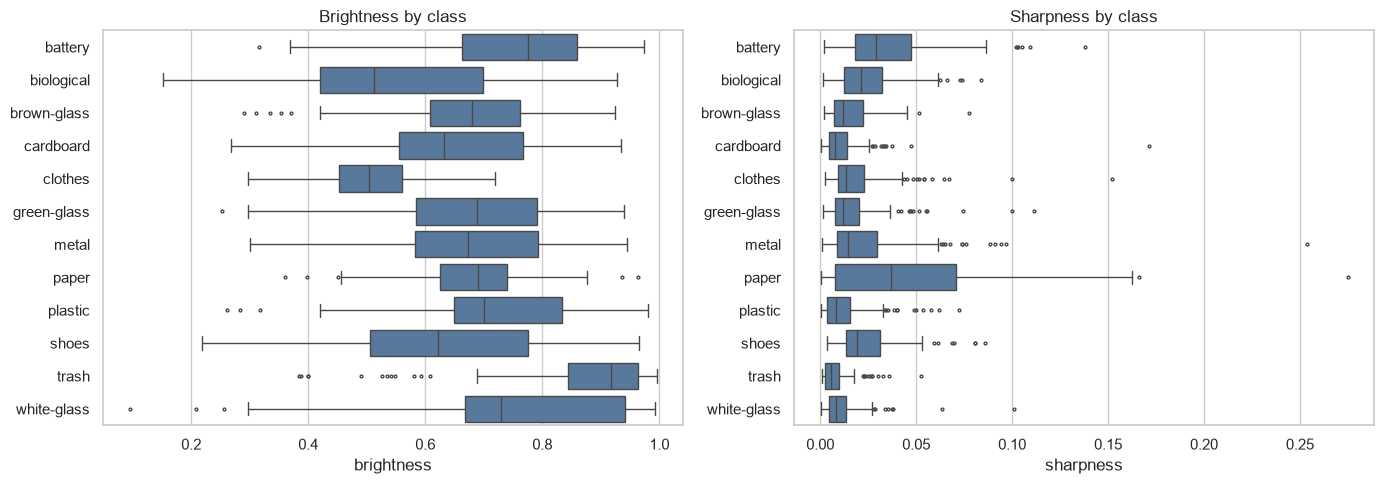

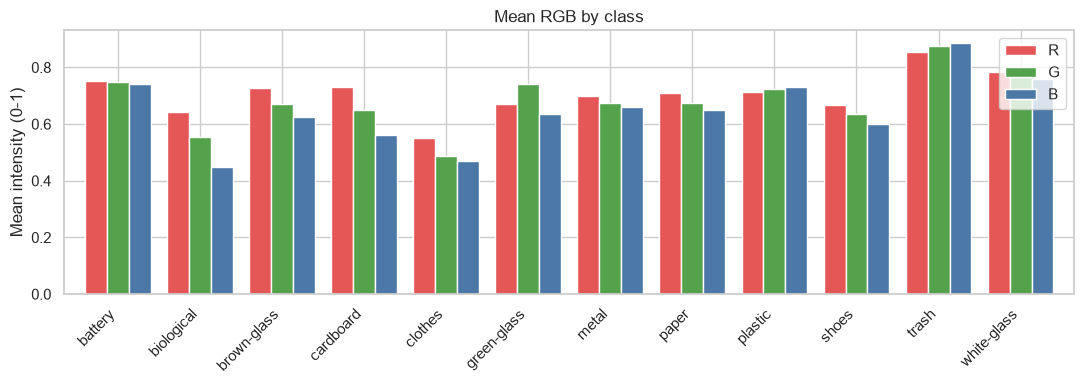

In [24]:
# [EDA 1.9] Thống kê độ sáng, độ nét, màu trung bình; mean/std RGB
stats = eda.compute_image_stats(df, n_per_class=150)
eda.plot_image_stats(stats)

<!-- @format -->

Kết quả cho thấy độ sáng khác nhau rõ rệt giữa các lớp. Lớp `trash` sáng nhất (median khoảng `0.92`, mean RGB khoảng `0.85` đến `0.88`) do hầu hết là vật thể trên nền trắng, trong khi `clothes` tối nhất (median khoảng `0.50`, mean RGB khoảng `0.47` đến `0.55`) và có khoảng giá trị khá hẹp. Màu sắc trung bình cũng mang thông tin của lớp: `biological` và `cardboard` thiên về đỏ, `green-glass` có kênh `G` cao nhất, còn `plastic`, `battery` và `white-glass` gần như trung tính.

Độ nét (phương sai Laplacian) cao nhất và phân tán nhất ở `paper`, thấp nhất ở `trash`, `plastic` và `cardboard`, đồng thời có nhiều giá trị ngoại lệ ở `metal` và `paper`. Vì độ nét phụ thuộc vào kết cấu bề mặt và nền ảnh nên không dùng để kết luận ảnh mờ giữa các lớp khác nhau.

Giá trị mean/std trên mẫu `1,800` ảnh cân bằng theo lớp là `(0.7083, 0.6840, 0.6475)` và `(0.2749, 0.2803, 0.3110)`. Các giá trị này sáng hơn đáng kể so với thống kê của ImageNet (mean `0.485, 0.456, 0.406`), do nhiều ảnh có nền trắng.

<!-- @format -->

### 1.10. Conclusion and preprocessing decisions

Phần này tổng hợp các phát hiện chính từ EDA và các quyết định tương ứng cho bước preprocessing và huấn luyện.

| Phát hiện | Quyết định |
|---|---|
| Không có ảnh lỗi, nhưng `113` ảnh (`RGBA`, `P`) không ở chế độ `RGB` | Chuyển toàn bộ ảnh về `RGB` khi đọc |
| `4` ảnh trùng, tạo `2` nhóm khác nhãn | Loại bỏ cả `4` ảnh |
| Mất cân bằng (`clothes` `33.3%`, `shoes` `12.6%`, tỷ lệ `8.54`) | Chia dữ liệu stratified, dùng class weight hoặc weighted sampler, đánh giá bằng `macro-F1`, recall theo lớp và confusion matrix |
| Kích thước phân cụm theo nguồn, tỷ lệ khung hình chủ yếu `0.75` đến `1.33` | Resize về `224x224` (hoặc resize `256` rồi crop), không kéo giãn hoặc pad để tránh lộ nguồn ảnh |
| Ảnh sáng hơn ImageNet (mean `0.71, 0.68, 0.65`) | Dùng mean/std của ImageNet nếu fine-tune mô hình pretrained; dùng mean/std của dataset nếu huấn luyện từ đầu |
| Nền và độ sáng gắn với lớp (`clothes` tối, `trash` sáng) | Dùng `RandomResizedCrop` và thay đổi độ sáng/tương phản ở mức vừa phải để mô hình bớt phụ thuộc vào nền |
| Ba lớp thủy tinh phân biệt bằng màu | Không dùng thay đổi hue mạnh hoặc chuyển ảnh xám; chỉ dùng lật ngang và xoay nhẹ |
| Các cặp lớp dễ nhầm: `clothes`/`shoes`, `paper`/`cardboard`, các loại `glass`, `white-glass`/`plastic` | Theo dõi riêng các cặp này trong confusion matrix khi đánh giá |
| Chỉ `70` ảnh được sửa nhãn (dưới `0.5%`) | Dùng bản `enhanced` làm dữ liệu chính, không trộn với bản `corrected` |

Tóm lại, dataset có chất lượng tương đối sạch (không ảnh lỗi, ít ảnh trùng, nhãn đã được rà soát) nhưng mất cân bằng đáng kể và có nguy cơ mô hình học theo nền, độ sáng và kích thước ảnh. Các quyết định trên nhằm xử lý những vấn đề này ngay từ bước preprocessing.